Check for pyTorch support for the GPU

In [1]:
import platform
import torch, torchvision

print("Python", platform.python_version(), "| PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("GPU:", p.name, f"| memory {p.total_memory / 1e9:.1f} GB")

Python 3.13.7 | PyTorch 2.14.1+cu126 | torchvision 0.29.1+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU | memory 6.4 GB


Get which classes belong to which crop

In [2]:
import json
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

SPLITS_DIR = Path("splits_v2")
classes = sorted(json.loads((SPLITS_DIR / "classes.json").read_text()), key=lambda c: c["index"])
CLASS_IDS = [c["id"] for c in classes]
CROPS = sorted({c["crop"] for c in classes})

crop_mask = torch.zeros(len(CROPS), len(CLASS_IDS), dtype=torch.bool)
for c in classes:
    crop_mask[CROPS.index(c["crop"]), c["index"]] = True

for i, crop in enumerate(CROPS):
    print(f"{crop:12s} {int(crop_mask[i].sum())} classes:", [CLASS_IDS[j] for j in crop_mask[i].nonzero().flatten()])

apple        3 classes: ['apple_scab', 'apple_cedar_rust', 'apple_healthy']
bell_pepper  2 classes: ['pepper_bacterial_spot', 'pepper_healthy']
corn         3 classes: ['corn_gray_leaf_spot', 'corn_northern_leaf_blight', 'corn_common_rust']
grape        2 classes: ['grape_black_rot', 'grape_healthy']
potato       2 classes: ['potato_early_blight', 'potato_late_blight']
tomato       8 classes: ['tomato_bacterial_spot', 'tomato_early_blight', 'tomato_late_blight', 'tomato_leaf_mold', 'tomato_septoria_leaf_spot', 'tomato_mosaic_virus', 'tomato_yellow_leaf_curl', 'tomato_healthy']


In [3]:
BACKBONES = {
    18: (models.resnet18, models.ResNet18_Weights.IMAGENET1K_V1),
    34: (models.resnet34, models.ResNet34_Weights.IMAGENET1K_V1),
    50: (models.resnet50, models.ResNet50_Weights.IMAGENET1K_V1),
}

class CropMaskedResNet(nn.Module):
    def __init__(self, depth, crop_mask, dropout=0.2, pretrained=True):
        super().__init__()
        build, weights = BACKBONES[depth]
        self.backbone = build(weights=weights if pretrained else None)
        n_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(n_features, crop_mask.shape[1]))
        self.register_buffer("crop_mask", crop_mask)

    def forward(self, images, crop_idx):
        logits = self.head(self.backbone(images))
        allowed = self.crop_mask[crop_idx]
        return logits.masked_fill(~allowed, -1e4)

In [4]:
def count_params(module):
    return sum(p.numel() for p in module.parameters())

for depth in (18, 34, 50):
    m = CropMaskedResNet(depth, crop_mask, pretrained=False)
    print(f"ResNet-{depth}: backbone {count_params(m.backbone):,} | head {count_params(m.head):,} | "
          f"total {count_params(m):,} | features per image {m.head[1].in_features}")

ResNet-18: backbone 11,176,512 | head 10,260 | total 11,186,772 | features per image 512
ResNet-34: backbone 21,284,672 | head 10,260 | total 21,294,932 | features per image 512
ResNet-50: backbone 23,508,032 | head 40,980 | total 23,549,012 | features per image 2048


Check the mask, then see the model layer by layer

In [5]:
model = CropMaskedResNet(18, crop_mask, pretrained=False).eval()
images = torch.randn(4, 3, 224, 224)                       # 4 fake images
crop_idx = torch.tensor([CROPS.index(c) for c in ["potato", "tomato", "apple", "potato"]])
targets = torch.tensor([CLASS_IDS.index(c) for c in ["potato_late_blight", "tomato_healthy", "apple_scab", "potato_early_blight"]])

with torch.no_grad():
    logits = model(images, crop_idx)
probs = logits.softmax(dim=1)
for k in range(4):
    nz = probs[k].nonzero().flatten()
    print(CROPS[crop_idx[k]], "->", {CLASS_IDS[j]: round(float(probs[k, j]), 3) for j in nz}, "| sum", round(float(probs[k].sum()), 3))
print("loss:", round(float(F.cross_entropy(logits, targets)), 3))

potato -> {'potato_early_blight': 0.924, 'potato_late_blight': 0.076} | sum 1.0
tomato -> {'tomato_bacterial_spot': 0.27, 'tomato_early_blight': 0.156, 'tomato_late_blight': 0.315, 'tomato_leaf_mold': 0.012, 'tomato_septoria_leaf_spot': 0.011, 'tomato_mosaic_virus': 0.025, 'tomato_yellow_leaf_curl': 0.027, 'tomato_healthy': 0.185} | sum 1.0
apple -> {'apple_scab': 0.112, 'apple_cedar_rust': 0.443, 'apple_healthy': 0.445} | sum 1.0
potato -> {'potato_early_blight': 0.904, 'potato_late_blight': 0.096} | sum 1.0
loss: 1.639


In [6]:
import pandas as pd

def shape_table(depth):
    m = CropMaskedResNet(depth, crop_mask, pretrained=False).eval()
    bb = m.backbone
    stages = [("input image", None),
              ("stem: conv 7x7 stride 2 + BN + ReLU", nn.Sequential(bb.conv1, bb.bn1, bb.relu)),
              ("max-pool 3x3 stride 2", bb.maxpool),
              ("stage 1 (layer1)", bb.layer1), ("stage 2 (layer2)", bb.layer2),
              ("stage 3 (layer3)", bb.layer3), ("stage 4 (layer4)", bb.layer4),
              ("global average pool", nn.Sequential(bb.avgpool, nn.Flatten())),
              ("dropout 0.2 + linear", m.head)]
    x = torch.zeros(1, 3, 224, 224)
    rows = []
    with torch.no_grad():
        for name, layer in stages:
            if layer is not None:
                x = layer(x)
            blocks = len(layer) if name.startswith("stage") else ""
            params = sum(p.numel() for p in layer.parameters()) if layer is not None else 0
            rows.append({"part": name, "blocks": blocks,
                         "output shape": " x ".join(map(str, x.shape[1:])),
                         "parameters": f"{params:,}"})
    rows.append({"part": "crop mask + softmax", "blocks": "",
                 "output shape": "probabilities over the crop's 2-8 classes", "parameters": "0"})
    return pd.DataFrame(rows)

shape_table(50)

,part,blocks,output shape,parameters
0,input image,,3 x 224 x 224,0
1,stem: conv 7x7 stride 2 + BN + ReLU,,64 x 112 x 112,"9,536"
2,max-pool 3x3 stride 2,,64 x 56 x 56,0
3,stage 1 (layer1),3,256 x 56 x 56,"215,808"
4,stage 2 (layer2),4,512 x 28 x 28,"1,219,584"
5,stage 3 (layer3),6,1024 x 14 x 14,"7,098,368"
6,stage 4 (layer4),3,2048 x 7 x 7,"14,964,736"
7,global average pool,,2048,0
8,dropout 0.2 + linear,,20,"40,980"
9,crop mask + softmax,,probabilities over the crop's 2-8 classes,0


In [7]:
shape_table(34)

,part,blocks,output shape,parameters
0,input image,,3 x 224 x 224,0
1,stem: conv 7x7 stride 2 + BN + ReLU,,64 x 112 x 112,"9,536"
2,max-pool 3x3 stride 2,,64 x 56 x 56,0
3,stage 1 (layer1),3,64 x 56 x 56,"221,952"
4,stage 2 (layer2),4,128 x 28 x 28,"1,116,416"
5,stage 3 (layer3),6,256 x 14 x 14,"6,822,400"
6,stage 4 (layer4),3,512 x 7 x 7,"13,114,368"
7,global average pool,,512,0
8,dropout 0.2 + linear,,20,"10,260"
9,crop mask + softmax,,probabilities over the crop's 2-8 classes,0


In [8]:
shape_table(18)

,part,blocks,output shape,parameters
0,input image,,3 x 224 x 224,0
1,stem: conv 7x7 stride 2 + BN + ReLU,,64 x 112 x 112,"9,536"
2,max-pool 3x3 stride 2,,64 x 56 x 56,0
3,stage 1 (layer1),2,64 x 56 x 56,"147,968"
4,stage 2 (layer2),2,128 x 28 x 28,"525,568"
5,stage 3 (layer3),2,256 x 14 x 14,"2,099,712"
6,stage 4 (layer4),2,512 x 7 x 7,"8,393,728"
7,global average pool,,512,0
8,dropout 0.2 + linear,,20,"10,260"
9,crop mask + softmax,,probabilities over the crop's 2-8 classes,0


Loading images

In [9]:
from plantdata import load_classes, read_manifest, PlantDataset
from pathlib import Path

SPLITS_DIR = Path("splits_v2")
CACHE_DIR = Path("cache_256")
CLASS_IDS, CROPS, crop_mask = load_classes(SPLITS_DIR)
manifest = read_manifest(CACHE_DIR)

datasets = {s: PlantDataset(manifest, s, CACHE_DIR, CROPS)
            for s in ["train", "val_lab", "test_lab", "val_wild", "test_wild"]}
for s, ds in datasets.items():
    print(f"{s:10s} {len(ds):6,} images")

image, crop_i, label = datasets["val_wild"][0]
print("\nfirst val_wild image:", image.size, "| crop:", CROPS[crop_i], "| class:", CLASS_IDS[label])
print(datasets["val_wild"].info.iloc[0].to_dict())

train      18,475 images
val_lab     3,972 images
test_lab    3,950 images
val_wild    1,630 images
test_wild   1,909 images

first val_wild image: (365, 256) | crop: apple | class: apple_scab
{'class_id': 'apple_scab', 'crop': 'apple', 'dataset': 'PlantDoc', 'source_split': 'test', 'rel_path': 'test/Apple Scab Leaf/052609%20Hartman%20Crabapple%20scab%20single%20leaf.JPG.jpg'}


Check for what augmentation does 

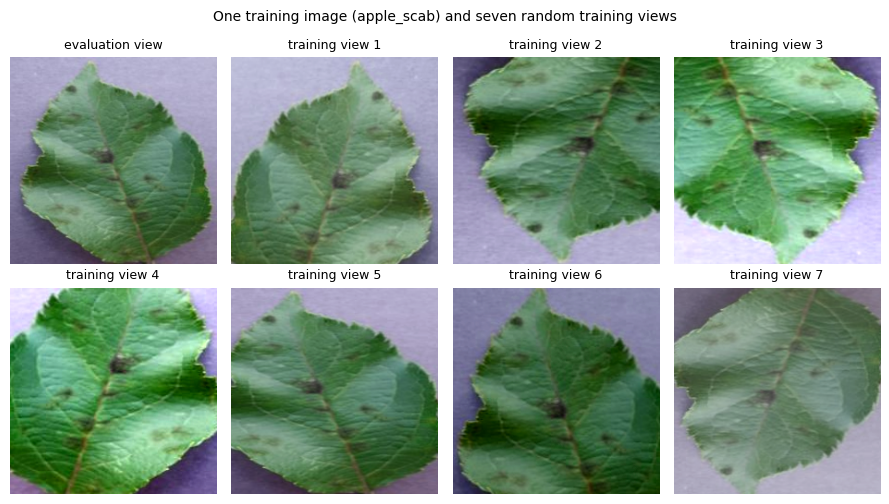

In [10]:
from plantdata import eval_transform, train_transform, IMAGENET_MEAN, IMAGENET_STD

def to_picture(x):
    """Undo the normalisation so a tensor can be shown as a picture."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

import matplotlib.pyplot as plt
torch.manual_seed(0)
show = PlantDataset(manifest, "train", CACHE_DIR, CROPS, transform=None)
i = 0
original = show[i][0]
aug = train_transform()

fig, axes = plt.subplots(2, 4, figsize=(9, 5.2))
for k, ax in enumerate(axes.flat):
    x = eval_transform()(original) if k == 0 else aug(original)
    ax.imshow(to_picture(x))
    ax.set_title("evaluation view" if k == 0 else f"training view {k}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"One training image ({CLASS_IDS[show[i][2]]}) and seven random training views", fontsize=10)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/q2_augmentation.png", dpi=200)
plt.show()

CPU side loading speed check

In [11]:
import os, time
from plantdata import make_loader

print("CPU cores:", os.cpu_count())
train_ds = PlantDataset(manifest, "train", CACHE_DIR, CROPS, train_transform())
for workers in [w for w in (0, 2, 4, 6, 8, 10) if w <= (os.cpu_count() or 2)]:
    loader = make_loader(train_ds, batch_size=64, train=True, num_workers=workers)
    it = iter(loader)
    next(it)                                   # start-up of the workers is not timed
    t0 = time.perf_counter()
    n = 0
    for _ in range(20):
        images, crop_b, labels = next(it)
        n += len(images)
    rate = n / (time.perf_counter() - t0)
    print(f"{workers} workers: {rate:,.0f} images/s  (batch shape {tuple(images.shape)})")
    del it, loader

CPU cores: 16
0 workers: 193 images/s  (batch shape (64, 3, 224, 224))
2 workers: 422 images/s  (batch shape (64, 3, 224, 224))
4 workers: 768 images/s  (batch shape (64, 3, 224, 224))
6 workers: 939 images/s  (batch shape (64, 3, 224, 224))
8 workers: 1,123 images/s  (batch shape (64, 3, 224, 224))
10 workers: 1,388 images/s  (batch shape (64, 3, 224, 224))


GPU side loading speed check

In [12]:
device = "cuda"
BATCH, STEPS, WARMUP = 64, 25, 5

for depth in (18, 34, 50):
    model = CropMaskedResNet(depth, crop_mask, pretrained=False).to(device).train()
    optimiser = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    scaler = torch.amp.GradScaler("cuda")
    x = torch.randn(BATCH, 3, 224, 224, device=device)
    crop_b = torch.randint(0, len(CROPS), (BATCH,), device=device)
    y = crop_mask.to(device)[crop_b].float().argmax(dim=1)     # a class that belongs to each image's crop
    torch.cuda.reset_peak_memory_stats()
    for step in range(STEPS):
        if step == WARMUP:
            torch.cuda.synchronize()
            t0 = time.perf_counter()
        with torch.autocast("cuda", dtype=torch.float16):
            loss = F.cross_entropy(model(x, crop_b), y)
        optimiser.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimiser)
        scaler.update()
    torch.cuda.synchronize()
    rate = (STEPS - WARMUP) * BATCH / (time.perf_counter() - t0)
    memory = torch.cuda.max_memory_allocated() / 1e9
    print(f"ResNet-{depth}: {rate:,.0f} images/s training | peak GPU memory {memory:.1f} GB | "
          f"one epoch of 18,475 images ≈ {18475 / rate / 60:.1f} min (GPU only)")
    del model, optimiser, x
    torch.cuda.empty_cache()

ResNet-18: 772 images/s training | peak GPU memory 1.0 GB | one epoch of 18,475 images ≈ 0.4 min (GPU only)
ResNet-34: 468 images/s training | peak GPU memory 1.5 GB | one epoch of 18,475 images ≈ 0.7 min (GPU only)
ResNet-50: 267 images/s training | peak GPU memory 3.2 GB | one epoch of 18,475 images ≈ 1.2 min (GPU only)


Scoring a model

In [13]:
from training import evaluate

device = "cuda"
torch.manual_seed(42)
val_wild = PlantDataset(manifest, "val_wild", CACHE_DIR, CROPS, eval_transform())
val_wild_loader = make_loader(val_wild, batch_size=128, train=False, num_workers=8)

model = CropMaskedResNet(18, crop_mask, pretrained=True).to(device)
result = evaluate(model, val_wild_loader, CLASS_IDS, device)
print({k: round(v, 3) for k, v in result.items()})

{'macro_f1_16_disease': 0.219, 'macro_f1_20': 0.218, 'late_blight_recall': 0.467, 'accuracy': 0.31, 'ms_per_image': 0.422}


In [14]:
import time
from training import freeze, make_optimiser, train_one_epoch

device = "cuda"
torch.manual_seed(42)
train_ds = PlantDataset(manifest, "train", CACHE_DIR, CROPS, train_transform(augment=False))
train_loader = make_loader(train_ds, batch_size=64, train=True, num_workers=8, seed=42)
val_lab_loader = make_loader(PlantDataset(manifest, "val_lab", CACHE_DIR, CROPS, eval_transform()),
                             batch_size=128, train=False, num_workers=8)
val_wild_loader = make_loader(PlantDataset(manifest, "val_wild", CACHE_DIR, CROPS, eval_transform()),
                              batch_size=128, train=False, num_workers=8)

model = CropMaskedResNet(18, crop_mask, pretrained=True).to(device)
frozen = freeze(model, "backbone")
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable weights: {trainable:,} of {sum(p.numel() for p in model.parameters()):,}")

optimiser = make_optimiser(model, "sgd", lr=0.01, weight_decay=1e-4)
scaler = torch.amp.GradScaler(device)
before = model.backbone.layer4[0].conv1.weight.clone()

for epoch in range(1, 4):
    t0 = time.perf_counter()
    loss, acc = train_one_epoch(model, train_loader, optimiser, scaler, device, frozen)
    lab = evaluate(model, val_lab_loader, CLASS_IDS, device)
    wild = evaluate(model, val_wild_loader, CLASS_IDS, device)
    print(f"epoch {epoch}: train loss {loss:.3f} acc {acc:.3f} | val_lab F1-16 {lab['macro_f1_16_disease']:.3f} | "
          f"val_wild F1-16 {wild['macro_f1_16_disease']:.3f} | {wild['ms_per_image']:.2f} ms/image | "
          f"{time.perf_counter() - t0:.0f} s")

print("backbone unchanged:", torch.equal(before, model.backbone.layer4[0].conv1.weight))

trainable weights: 10,260 of 11,186,772
epoch 1: train loss 0.414 acc 0.855 | val_lab F1-16 0.879 | val_wild F1-16 0.328 | 0.47 ms/image | 146 s
epoch 2: train loss 0.247 acc 0.912 | val_lab F1-16 0.904 | val_wild F1-16 0.322 | 0.45 ms/image | 101 s
epoch 3: train loss 0.214 acc 0.925 | val_lab F1-16 0.922 | val_wild F1-16 0.356 | 0.43 ms/image | 42 s
backbone unchanged: True
